# DL · 01 Data Preparation for the Neural Network
**Project 18: Water Quality Prediction — Part B, Deep Learning (PyTorch MLP)**

This part trains a feedforward neural network (multilayer perceptron) to estimate the continuous `CCME_Values` index (0–100) from eight water measurements. The gradient-boosting part lives separately in `AML/`.

Run the DL notebooks in order: **01_data_preparation → 02_mlp_training → 03_final_model**.

**Read this first:** the released index is calculated from the same eight measurements, so this is an index-emulation experiment — not an independent water-quality or drinking-water safety prediction.

**Project team**

| Team member | Enrollment number |
|---|---|
| Dhruv Kumar | 2401010152 |
| Ritesh | 2041010383 |
| Yash Kumar | 2401010512 |
| Parul | 2401010321 |
| Punit | 2401010359 |

## 1. Environment
Tested with Python 3.12. Install the dependencies once (see the repository README), then restart the kernel:
```python
%pip install numpy==2.3.4 pandas==2.3.3 scikit-learn==1.7.2 torch==2.9.1 matplotlib joblib==1.6.0 ipykernel
```

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image
import joblib
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
# Locate the repository root from either the repo root or the notebook folder.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "Datasets" / "Water_Quality_Dataset.zip").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
PART = ROOT / "DL"              # This part of the project
DATA = ROOT / "Datasets"            # Shared source data
CACHE = DATA / "_working"           # Shared extracted CSV; ignored by Git
WORK = PART / "_working"            # Intermediate files for this part; ignored by Git
FIGURES = PART / "figures"
MODELS = PART / "Models"
RESULTS = PART / "Results"
for folder in [CACHE, WORK, FIGURES, MODELS, RESULTS]:
    folder.mkdir(exist_ok=True)
CSV = CACHE / "Combined_dataset.csv"
EXPECTED_SHA256 = "81ced159f465aa5ab004b77130e5f7147c698876ddbf2f97807e31c9d0e8d714"
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = ["Ammonia", "BOD", "Dissolved oxygen", "Orthophosphate", "pH", "Temperature", "Nitrogen", "Nitrate"]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]
BANDS = ["Poor", "Marginal", "Fair", "Good", "Excellent"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_csv():
    """Extract the unmodified Figshare CSV from the shared ZIP once, then verify it."""
    if not CSV.exists():
        archive = DATA / "Water_Quality_Dataset.zip"
        if archive.exists():
            import shutil
            with zipfile.ZipFile(archive) as z, z.open("Combined_dataset.csv") as src, CSV.open("wb") as dst:
                shutil.copyfileobj(src, dst)
        else:
            import urllib.request
            urllib.request.urlretrieve("https://ndownloader.figshare.com/files/50757321", CSV)
    assert sha256(CSV) == EXPECTED_SHA256, "Dataset checksum differs from the documented release."
    return CSV


def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result


def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for review, not converted. Every input gets a
    fixed missing/invalid flag, so the model always receives 16 columns.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)


def dump_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n")

CONFIG = {
    "seed": 42,
    "train_end": "2018-12-31", "validation_end": "2019-12-31", "calibration_end": "2020-12-31",
    "sample_train_rows": 300000,   # only for the original small-sample reference run
    "alpha": 0.1, "explanation_rows": 2000,
}
CONFIG["data"] = str(CSV)

## 2. Load, verify and clean the whole dataset
The shared ZIP in `Datasets/` holds the unchanged Figshare CSV (2,827,977 rows). We remove exact duplicates, keep source-row IDs for traceability and never impute a target or a date.

In [2]:
def read_dataset(path):
    df = pd.read_csv(path)
    required = set(META + FEATURES + [TARGET, "CCME_WQI"])
    if required - set(df.columns):
        raise ValueError(f"Dataset lacks columns: {sorted(required - set(df.columns))}")
    return df

def prepare(frame):
    """Keep source row IDs for traceability; never impute a target or a date."""
    df = frame.copy()
    df.insert(0, "source_row", np.arange(len(df)))
    duplicates = df.drop(columns="source_row").duplicated()
    date = pd.to_datetime(df.Date, format="%d-%m-%Y", errors="coerce")
    y = pd.to_numeric(df[TARGET], errors="coerce")
    invalid = date.isna() | ~y.between(0, 100) | df.Country.isna() | df.Area.isna()
    counts = {
        "exact_duplicates_removed": int(duplicates.sum()),
        "invalid_metadata_or_target": int(invalid.sum()),
    }
    df = df.loc[~duplicates & ~invalid].copy()
    df["parsed_date"] = date.loc[df.index]
    df[TARGET] = y.loc[df.index]
    return df, counts

def temporal_split(df, config):
    bounds = [pd.Timestamp(config[k]) for k in ["train_end", "validation_end", "calibration_end"]]
    if not bounds[0] < bounds[1] < bounds[2]:
        raise ValueError("Split boundaries must increase strictly")
    date = df.parsed_date
    masks = [
        date <= bounds[0],
        (date > bounds[0]) & (date <= bounds[1]),
        (date > bounds[1]) & (date <= bounds[2]),
        date > bounds[2],
    ]
    splits = dict(zip(["train", "validation", "calibration", "test"], [df.loc[m].copy() for m in masks]))
    if any(part.empty for part in splits.values()):
        raise ValueError("Every chronological partition must contain observations")
    return splits

def sample(frame, cap, seed):
    if cap and len(frame) > cap:
        return frame.sample(n=cap, random_state=seed).sort_index()
    return frame

def split_summary(part):
    return {
        "rows": len(part),
        "start": str(part.parsed_date.min().date()),
        "end": str(part.parsed_date.max().date()),
        "countries": part.Country.value_counts().to_dict(),
        "sites": int(part.groupby(["Country", "Area"]).ngroups),
        "mean_target": float(part[TARGET].mean()),
    }

raw = read_dataset(ensure_csv())
print(f"Verified source: {len(raw):,} rows x {len(raw.columns)} columns")
clean, removed = prepare(raw)
del raw
print(removed)
print(f"Rows kept for modelling: {len(clean):,}")

Verified source: 2,827,977 rows x 14 columns


{'exact_duplicates_removed': 9971, 'invalid_metadata_or_target': 0}
Rows kept for modelling: 2,818,006


## 3. Chronological partitions — and this time we use all of the training data
| Partition | Dates | Role in the DL part |
|---|---|---|
| Training | 1940–2018 | **All rows** fit the network (the original study used a 300,000-row sample) |
| Validation | 2019 | Architecture selection and best-epoch checkpoint |
| Calibration | 2020 | 90% residual interval radius |
| Test | 2021–2023 | Final, untouched evaluation |

After evaluation, the final model is refitted once on **every year (1940–2023)** for deployment.

In [3]:
splits = temporal_split(clean, CONFIG)
manifest = {key: split_summary(part) for key, part in splits.items()}
manifest["retained_rows"] = len(clean)
manifest.update(removed)
train_sites = pd.MultiIndex.from_frame(splits["train"][["Country", "Area"]])
test_sites = pd.MultiIndex.from_frame(splits["test"][["Country", "Area"]])
manifest["test_rows_at_sites_seen_before_2019"] = float(test_sites.isin(train_sites).mean())
display(pd.DataFrame({k: v for k, v in manifest.items() if isinstance(v, dict)}).T[["rows", "start", "end", "sites", "mean_target"]])

,rows,start,end,sites,mean_target
train,2478761,1940-01-02,2018-12-28,55731,84.148022
validation,87177,2019-01-01,2019-12-31,14705,90.376429
calibration,49182,2020-01-01,2020-12-31,11484,91.920604
test,202886,2021-01-01,2023-12-17,17462,91.410002


## 4. Neural-network input pipeline
Neural networks train poorly on raw concentrations that span several orders of magnitude, so every input goes through three steps fitted **on training rows only**:

1. **Quality flags** — invalid readings become missing and get a 0/1 flag (8 measurements → 16 inputs).
2. **Median imputation** for any missing value.
3. **`asinh` + standardization** — `asinh` compresses heavy right tails (and still works for sub-zero temperatures); standardization gives every input mean 0 and variance 1, so gradient descent treats them evenly.

In [4]:
neural_pre = make_pipeline(
    SimpleImputer(strategy="median", keep_empty_features=True),
    FunctionTransformer(np.arcsinh, validate=False),
    StandardScaler(),
)
raw_train = quality_features(splits["train"])
xf = neural_pre.fit_transform(raw_train).astype("float32")
yf = splits["train"][TARGET].to_numpy("float32")

def transform(part):
    return neural_pre.transform(quality_features(part)).astype("float32"), part[TARGET].to_numpy("float32")

xv, yv = transform(splits["validation"])
xc, yc = transform(splits["calibration"])
xt, yt = transform(splits["test"])
# The original study's 300,000-row training sample, kept for a before/after comparison.
sample_ids = splits["train"].index.get_indexer(sample(splits["train"], CONFIG["sample_train_rows"], CONFIG["seed"]).index)
assert xf.shape[1] == 16 and np.isfinite(xf).all() and np.isfinite(xt).all()
print(f"Full training inputs: {xf.shape}; sample rows: {len(sample_ids):,}")
print(f"Validation {xv.shape}, calibration {xc.shape}, test {xt.shape}")

Full training inputs: (2478761, 16); sample rows: 300,000
Validation (87177, 16), calibration (49182, 16), test (202886, 16)


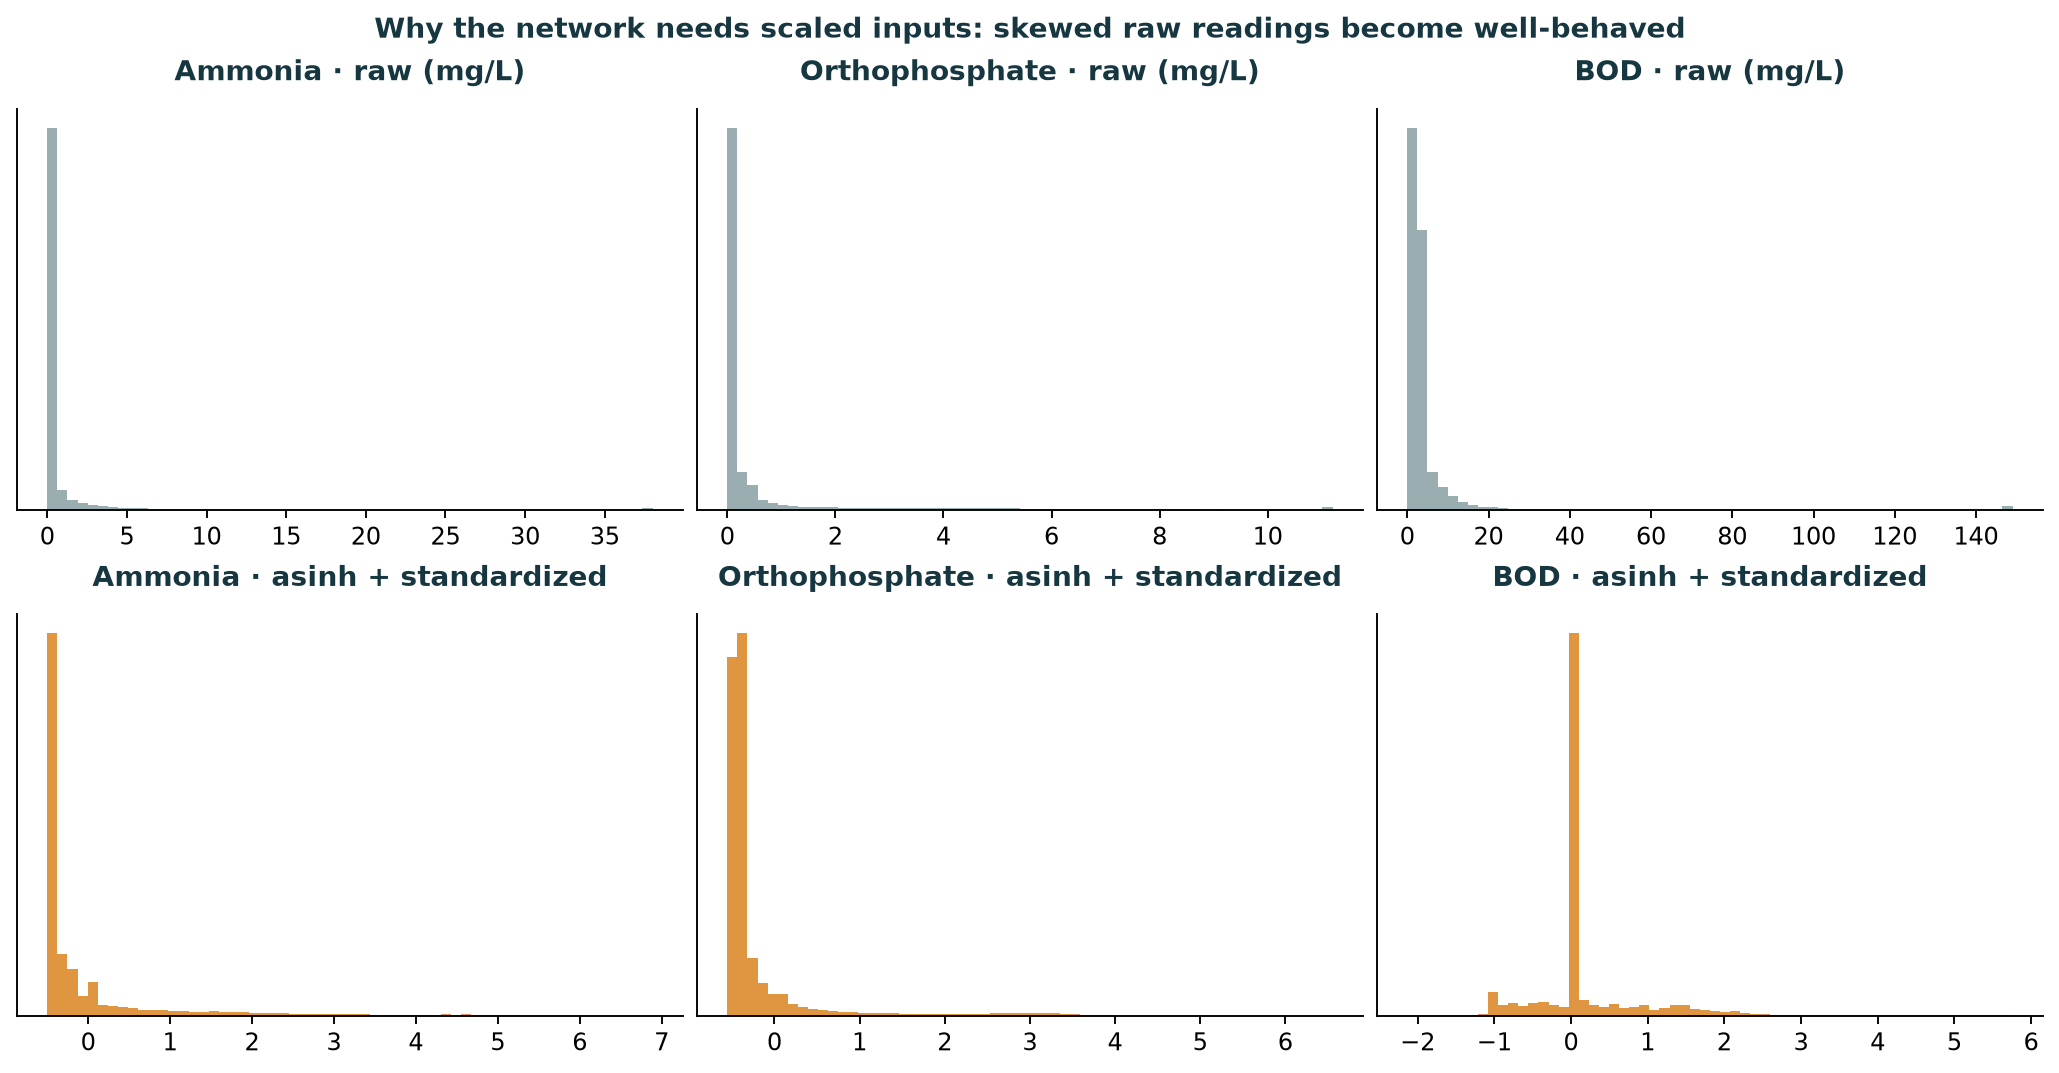

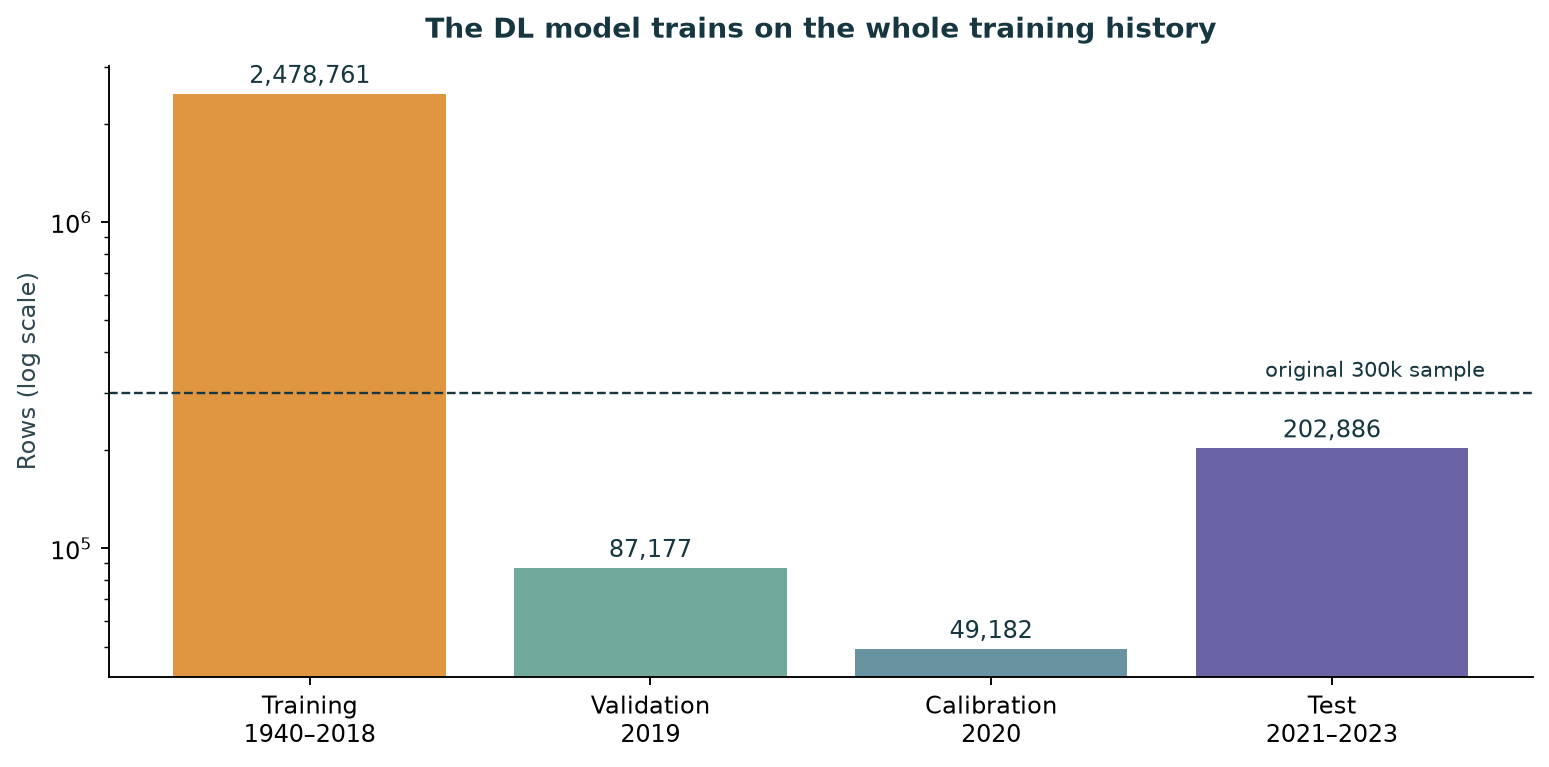

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#314a52", "text.color": "#163640",
                     "axes.titleweight": "bold", "axes.titlepad": 12,
                     "grid.color": "#dfe9ea", "axes.axisbelow": True})

def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), layout="constrained")
for j, (col, short) in enumerate([(FEATURES[0], "Ammonia"), (FEATURES[3], "Orthophosphate"), (FEATURES[1], "BOD")]):
    values = raw_train[col].dropna().sample(n=200000, random_state=42)
    axes[0, j].hist(values.clip(upper=values.quantile(0.995)), bins=60, color="#9aaeb2")
    axes[0, j].set(title=f"{short} · raw (mg/L)", yticks=[])
    k = FEATURES.index(col)
    axes[1, j].hist(xf[:200000, k], bins=60, color="#e09540")
    axes[1, j].set(title=f"{short} · asinh + standardized", yticks=[])
fig.suptitle("Why the network needs scaled inputs: skewed raw readings become well-behaved", fontweight="bold")
show_figure(fig, "input_scaling.png")

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
parts = ["train", "validation", "calibration", "test"]
counts = [manifest[k]["rows"] for k in parts]
bars = ax.bar(["Training\n1940–2018", "Validation\n2019", "Calibration\n2020", "Test\n2021–2023"], counts,
              color=["#e09540", "#71a99d", "#6893a1", "#6a63a6"])
ax.axhline(CONFIG["sample_train_rows"], color="#163640", linestyle="--", linewidth=1)
ax.text(3.45, CONFIG["sample_train_rows"] * 1.12, "original 300k sample", ha="right", fontsize=9)
ax.set(yscale="log", ylabel="Rows (log scale)", title="The DL model trains on the whole training history")
for i, count in enumerate(counts):
    ax.text(i, count * 1.08, f"{count:,}", ha="center")
show_figure(fig, "temporal_split.png")

## 5. Save the local preparation cache
`DL/_working/` is a disposable cache (excluded from Git) used by the next two notebooks.

In [6]:
explain_frame = sample(splits["validation"], CONFIG["explanation_rows"], CONFIG["seed"])
test_meta = splits["test"][["source_row", "Country", "Area", "Date", "CCME_WQI", TARGET]].reset_index(drop=True)
bundle = {
    "config": CONFIG, "manifest": manifest, "neural_pre": neural_pre,
    "xf": xf, "yf": yf, "sample_ids": sample_ids,
    "xv": xv, "yv": yv, "xc": xc, "yc": yc, "xt": xt, "yt": yt,
    "test_meta": test_meta, "test_raw": splits["test"][FEATURES].reset_index(drop=True),
    "explain_frame": explain_frame[FEATURES + [TARGET]],
}
joblib.dump(bundle, WORK / "prepared.joblib", compress=0)
dump_json(WORK / "split_manifest.json", manifest)
print(f"Saved {WORK / 'prepared.joblib'} ({(WORK / 'prepared.joblib').stat().st_size / 1024**2:.0f} MiB)")

Saved /Users/yashkumar/aiml_project/DL/_working/prepared.joblib (205 MiB)


## Next step
Run **02_mlp_training.ipynb** to compare network designs on the full training set.